## Análise 2: grau de risco x tipo de ação
Pergunta: a resposta da Defesa Civil muda conforme o grau de risco? A consulta cruza a fato com a **dim_tipo_acao** e a **dim_risco** e calcula, para cada categoria de ação, quanto dos atendimentos ocorreu em cada grau de risco (R1 a R4). Ficam de fora as linhas sem ação ou sem risco informados.

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv("../.env")
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

### Consulta

In [4]:
# mesma consulta salva em analises/analise_2_risco_x_tipo_acao.sql
consulta = open("../analises/analise_2_risco_x_tipo_acao.sql", encoding="utf-8").read()
resultado = pd.read_sql(consulta, con=engine)
resultado

,categoria_acao,codigo_risco,descricao_risco,atendimentos,percentual_na_categoria
0,Assistência humanitária,R1,baixo,1,9.1
1,Assistência humanitária,R2,médio,2,18.2
2,Assistência humanitária,R3,alto,4,36.4
3,Assistência humanitária,R4,muito alto,4,36.4
4,Assistência social,R1,baixo,1621,5.0
5,Assistência social,R2,médio,6585,20.4
6,Assistência social,R3,alto,23461,72.7
7,Assistência social,R4,muito alto,624,1.9
8,Avaliação técnica de risco,R1,baixo,3989,14.4
9,Avaliação técnica de risco,R2,médio,7882,28.4


### Gráfico 1: Distribuição do grau de risco dos atendimentos por categoria de ação (2022 a 2024)

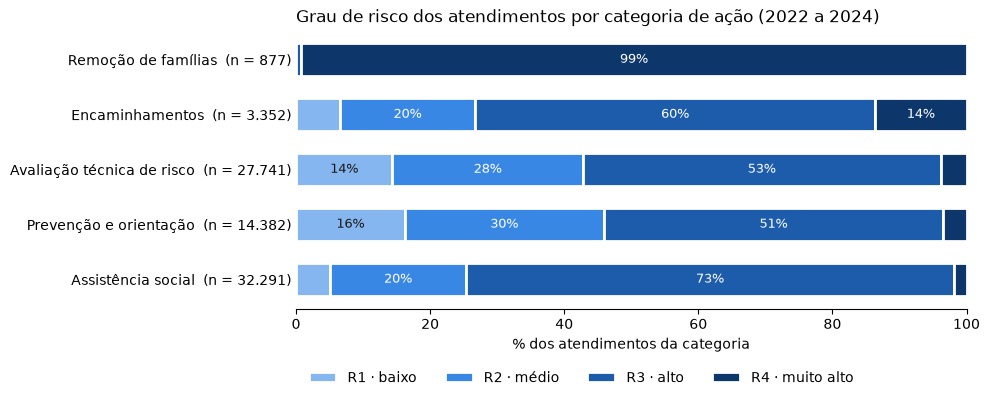

In [5]:
# resultado da consulta em formato de tabela: uma linha por categoria, uma coluna por grau de risco
tabela = resultado.pivot(index="categoria_acao", columns="codigo_risco", values="atendimentos").fillna(0)
tabela = tabela[["R1", "R2", "R3", "R4"]]
total = tabela.sum(axis=1)
percentual = tabela.div(total, axis=0) * 100

# só categorias com pelo menos 100 atendimentos com risco informado, ordenadas pela fatia de R4
percentual = percentual[total >= 100].sort_values("R4")
rotulos = [f"{cat}  (n = {int(total[cat]):,})".replace(",", ".") for cat in percentual.index]

CORES = {"R1": "#86b6ef", "R2": "#3987e5", "R3": "#1c5cab", "R4": "#0d366b"}  # um tom de azul, do claro (baixo) ao escuro (muito alto)
NOMES = {"R1": "R1 · baixo", "R2": "R2 · médio", "R3": "R3 · alto", "R4": "R4 · muito alto"}

fig, ax = plt.subplots(figsize=(10, 4.2))
inicio = [0] * len(percentual)
for codigo in ["R1", "R2", "R3", "R4"]:
    valores = percentual[codigo].values
    barras = ax.barh(rotulos, valores, left=inicio, color=CORES[codigo], label=NOMES[codigo],
                     height=0.6, edgecolor="white", linewidth=2)
    # escreve o percentual só nos pedaços grandes o bastante
    for barra, valor in zip(barras, valores):
        if valor >= 8:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_y() + barra.get_height() / 2,
                    f"{valor:.0f}%", ha="center", va="center", fontsize=9,
                    color="#1a1a19" if codigo == "R1" else "white")
    inicio = [a + b for a, b in zip(inicio, valores)]

ax.set_xlim(0, 100)
ax.set_xlabel("% dos atendimentos da categoria")
ax.set_title("Grau de risco dos atendimentos por categoria de ação (2022 a 2024)", loc="left", fontsize=12)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("analise_2_risco_x_tipo_acao.png", dpi=150, bbox_inches="tight")
plt.show()


### Quando aconteceram as remoções de famílias

In [6]:
consulta = open("../analises/analise_2_remocoes_por_mes.sql", encoding="utf-8").read()
remocoes = pd.read_sql(consulta, con=engine)
remocoes

,ano,mes,nome_mes,remocoes
0,2022,5,maio,66
1,2022,6,junho,373
2,2022,7,julho,349
3,2022,8,agosto,92
4,2022,9,setembro,4
5,2023,2,fevereiro,71
6,2023,4,abril,1
7,2023,5,maio,4
8,2023,6,junho,2
9,2023,7,julho,4


### Gráfico 2: Composição das ações em cada grau de risco (2022 a 2024)

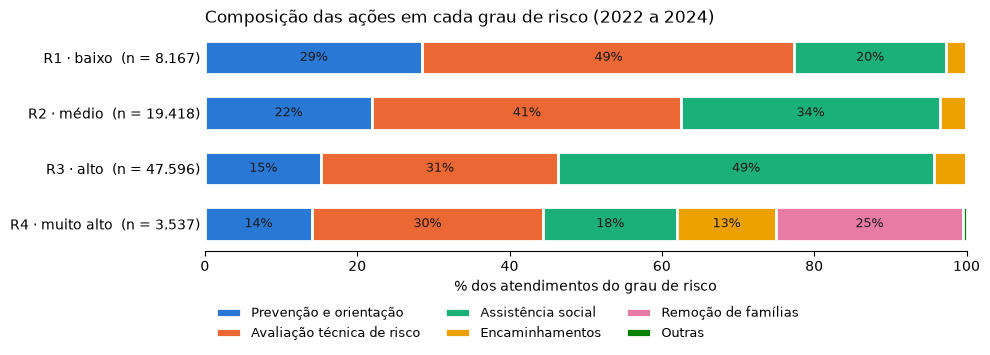

In [7]:
consulta = open("../analises/analise_2_prevencao_por_risco.sql", encoding="utf-8").read()
composicao = pd.read_sql(consulta, con=engine)

ORDEM_CATEGORIAS = ["Prevenção e orientação", "Avaliação técnica de risco", "Assistência social",
                    "Encaminhamentos", "Remoção de famílias", "Outras"]
CORES_CATEGORIAS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

# junta as categorias com menos de 1% em todos os graus (manutenção e assistência humanitária) em "Outras"
composicao["categoria"] = composicao["categoria_acao"].where(
    composicao["categoria_acao"].isin(ORDEM_CATEGORIAS), "Outras")
tabela_comp = (composicao.pivot_table(index="codigo_risco", columns="categoria",
                                      values="atendimentos", aggfunc="sum", fill_value=0)
               .reindex(index=["R4", "R3", "R2", "R1"], columns=ORDEM_CATEGORIAS, fill_value=0))
total_risco = tabela_comp.sum(axis=1)
pct_comp = tabela_comp.div(total_risco, axis=0) * 100
NOMES_RISCO = {"R1": "R1 · baixo", "R2": "R2 · médio", "R3": "R3 · alto", "R4": "R4 · muito alto"}
rotulos_risco = [f"{NOMES_RISCO[r]}  (n = {int(total_risco[r]):,})".replace(",", ".") for r in pct_comp.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
inicio = [0] * len(pct_comp)
for categoria, cor in zip(ORDEM_CATEGORIAS, CORES_CATEGORIAS):
    valores = pct_comp[categoria].values
    barras = ax.barh(rotulos_risco, valores, left=inicio, color=cor, label=categoria,
                     height=0.6, edgecolor="white", linewidth=2)
    for barra, valor in zip(barras, valores):
        if valor >= 8:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_y() + barra.get_height() / 2,
                    f"{valor:.0f}%", ha="center", va="center", fontsize=9, color="#1a1a19")
    inicio = [a + b for a, b in zip(inicio, valores)]

ax.set_xlim(0, 100)
ax.set_xlabel("% dos atendimentos do grau de risco")
ax.set_title("Composição das ações em cada grau de risco (2022 a 2024)", loc="left", fontsize=12)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.2), frameon=False, fontsize=9)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("analise_2_composicao_por_risco.png", dpi=150, bbox_inches="tight")
plt.show()

### Onde aconteceram as remoções de famílias no ano de 2022

In [8]:
consulta = open("../analises/analise_2_remocoes_por_localidade.sql", encoding="utf-8").read()
remocoes = pd.read_sql(consulta, con=engine)
remocoes

,bairro,localidade,remocoes
0,Cohab,Jardim Monte Verde,310
1,Barro,Parque Dos Milagres,129
2,Cohab,Ur 02,82
3,Barro,Vila Dos Milagres,63
4,Cohab,Ur 03,49
5,Coqueiral,Alto Da Bela Vista,45
6,Coqueiral,Coqueiral,41
7,Cohab,Ur 01,36
8,Caxanga,NaN,22
9,Varzea,NaN,16


### Gráfico 3:  localidades com mais remoções de famílias em 2022

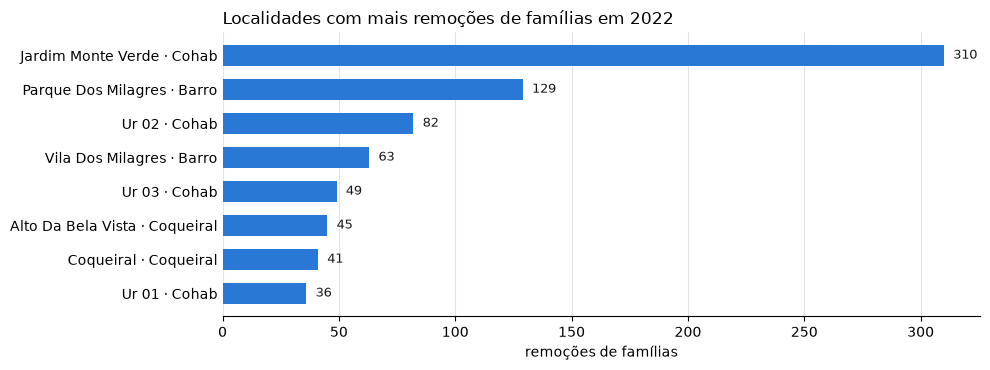

In [13]:
consulta = open("../analises/analise_2_remocoes_por_localidade.sql", encoding="utf-8").read()
localidades = pd.read_sql(consulta, con=engine).head(8)
localidades["rotulo"] = localidades["localidade"].fillna("(sem localidade)") + " · " + localidades["bairro"]
localidades = localidades.iloc[::-1]  # maior no topo

fig, ax = plt.subplots(figsize=(10, 3.8))
barras = ax.barh(localidades["rotulo"], localidades["remocoes"], color="#2a78d6", height=0.6)
for barra, valor in zip(barras, localidades["remocoes"]):
    ax.text(barra.get_width() + 4, barra.get_y() + barra.get_height() / 2, str(valor),
            va="center", fontsize=9, color="#1a1a19")
ax.set_xlabel("remoções de famílias")
ax.set_title("Localidades com mais remoções de famílias em 2022", loc="left", fontsize=12)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("analise_2_remocoes_por_localidade.png", dpi=150, bbox_inches="tight")
plt.show()


### Composição das ações por grau de risco

In [9]:
consulta = open("../analises/analise_2_prevencao_por_risco.sql", encoding="utf-8").read()
pd.read_sql(consulta, con=engine)

,codigo_risco,categoria_acao,atendimentos,percentual_no_risco
0,R1,Avaliação técnica de risco,3989,48.8
1,R1,Prevenção e orientação,2333,28.6
2,R1,Assistência social,1621,19.8
3,R1,Encaminhamentos,220,2.7
4,R1,Manutenção e obras,3,0.0
5,R1,Assistência humanitária,1,0.0
6,R2,Avaliação técnica de risco,7882,40.6
7,R2,Assistência social,6585,33.9
8,R2,Prevenção e orientação,4266,22.0
9,R2,Encaminhamentos,675,3.5


### Atendimentos em áreas R4 ao longo de 2022

In [10]:
consulta = open("../analises/analise_2_r4_por_mes.sql", encoding="utf-8").read()
pd.read_sql(consulta, con=engine)

,mes,nome_mes,atendimentos_r4
0,1,janeiro,21
1,2,fevereiro,24
2,3,março,59
3,4,abril,45
4,5,maio,361
5,6,junho,737
6,7,julho,492
7,8,agosto,240
8,9,setembro,115
9,10,outubro,77


### Para onde foram as famílias removidas

In [11]:
consulta = open("../analises/analise_2_destino_remocoes.sql", encoding="utf-8").read()
pd.read_sql(consulta, con=engine)

,tipo_acao,remocoes,remocoes_chuvas_2022
0,Remoção de Famílias (Auxílio Moradia),544,465
1,Remoção de Famílias (Casa de Parentes),403,381
2,Remoção de Famílias (Imóvel Alugado),25,24
3,Remoção de Famílias (Abrigos),15,9
4,Remoção de Famílias (Imóveis Alagados),3,0


### Quanto de cada categoria não tem grau de risco registrado

In [12]:
consulta = open("../analises/analise_2_risco_ausente_por_categoria.sql", encoding="utf-8").read()
pd.read_sql(consulta, con=engine)

,categoria_acao,atendimentos,percentual_sem_risco
0,Assistência humanitária,3923,99.7
1,Manutenção e obras,8118,99.2
2,Prevenção e orientação,33248,56.7
3,Assistência social,68324,52.7
4,Avaliação técnica de risco,50675,45.3
5,Encaminhamentos,4688,28.4
6,Remoção de famílias,990,11.4


### Insights

A resposta acompanha a gravidade do risco. A remoção de famílias concentra-se quase totalmente nas áreas de risco muito alto: 99,2% das remoções com risco informado ocorreram em áreas R4 (Figura 1). Nas demais categorias com mais de 100 atendimentos, o R4 representa entre 1,9% e 13,6%. Olhando pelo outro lado (Figura 2), a remoção não aparece em nenhum grau abaixo de R4 e passa a representar 24,6% dos atendimentos em R4.

A atuação muda de perfil conforme o risco sobe. Em R1, quase metade dos atendimentos (48,8%) é de avaliação técnica de risco, e a prevenção e orientação responde por 28,6%. Com o risco maior, essas duas participações caem, e a prevenção chega a 14,1% em R4. Em R3, a resposta mais comum é a assistência social (49,3%). Em R4, crescem a remoção e os encaminhamentos a outros órgãos (12,9%, contra 2,7% a 4,2% nos demais graus). O padrão sugere uma progressão: avaliar e orientar quando o risco é baixo, assistir as famílias quando é alto e retirá-las ou acionar parceiros quando é muito alto.

As remoções têm um lugar e um momento. Das 990 remoções de famílias, 879 (89%) ocorreram entre 25 de maio e 31 de agosto de 2022, durante as chuvas que causaram 126 mortes em Pernambuco [[1]](#referencias) e cujo efeito sobre a demanda mensal é analisado na seção 6.3. A localidade com mais remoções foi o Jardim Monte Verde, no bairro Cohab, com 310 (Figura 3), mais que o dobro da segunda colocada. Ali, um deslizamento de terra deixou 48 mortos, número que inclui o lado de Jaboatão dos Guararapes, que não faz parte desta base [[2]](#referencias). As oito localidades com mais remoções ficam em apenas três bairros: Cohab, Barro e Coqueiral.

A maioria das famílias foi para fora do sistema de abrigos. Das 990 remoções, 544 foram com auxílio-moradia e 403 para casa de parentes; apenas 15 foram para abrigos. Mesmo no auge das chuvas de 2022, quando ocorreram 879 remoções, só 9 famílias foram abrigadas. A resposta dependeu, portanto, de benefício financeiro e da rede familiar, e não de alojamento público.

Limitações do banco: 54% dos atendimentos não têm grau de risco registrado, e essa proporção subiu de 51% em 2022 para 61% em 2024. A ausência é desigual entre as categorias (consulta complementar 2): 56,7% das ações de prevenção não têm risco informado, contra 11,4% das remoções, o que provavelmente sub-representa a prevenção em todos os graus e pede cautela na comparação entre elas. Os dados também descrevem atendimentos, e não áreas: não é possível saber quantas áreas R4 existem nem quanta prevenção cada uma recebeu. Por fim, a classificação de risco não determina, por si só, a remoção: a revisão de 2026 do método de mapeamento alerta que setores R3 e R4 não devem ser tratados como se todas as moradias tivessem a mesma condição, sendo necessária análise caso a caso [[3]](#referencias). Por isso, os resultados mostram uma associação entre risco e tipo de ação, e não uma regra de atuação.

### Referências
<a id="referencias"></a>

1. FOLHA DE PERNAMBUCO. *Maior tragédia do século em Pernambuco, mortes pelas chuvas de 2022 superam total da cheia de 1975*. 2 jun. 2022. Disponível em: https://www.folhape.com.br/noticia/detalhe/maior-tragedia-do-seculo-em-pernambuco-mortes-pelas-chuvas-de-2022/228963/
2. DIARIO DE PERNAMBUCO. *Quatro anos após tragédia, governo entrega obra de contenção de encostas em Jardim Monte Verde*. 29 jun. 2026. Disponível em: https://www.diariodepernambuco.com.br/vida-urbana/2026/06/11717708-quatro-anos-apos-tragedia-governo-entrega-obra-de-contencao-de-encostas-em-jardim-monte-verde.html
3. GPPDC/UFJF. *De 2007 a 2026: o que mudou no modo brasileiro de mapear riscos*. 2 set. 2026. Disponível em: https://www2.ufjf.br/gppdc/2026/09/02/de-2007-a-2026-o-que-mudou-no-modo-brasileiro-de-mapear-riscos/
4. PREFEITURA DO RECIFE. *Registro de Atendimentos da Defesa Civil*. Portal de Dados Abertos do Recife. Disponível em: https://dados.recife.pe.gov.br/dataset/registro-de-atendimentos-da-defesa-civil